In [1]:
!pip install -q datasets xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier

import pickle
import warnings

warnings.filterwarnings("ignore")

In [3]:
dataset = load_dataset(
    "Kshitijbhatt1998/ieee-fraud-detection-pipeline-features"
)

README.md:   0%|          | 0.00/5.00k [00:00<?, ?B/s]

fraud_features.parquet: reconstructing file:   0%|          |  0.00B / 35.1MB            

fraud_features.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/590540 [00:00<?, ? examples/s]

In [4]:
dataset

DatasetDict({
    train: Dataset({
        features: ['transaction_id', 'transaction_dt', 'transaction_ts', 'transaction_amt', 'log_amt', 'hour_of_day', 'day_of_week', 'product_cd', 'has_identity', 'is_fraud', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'purchaser_email_domain', 'recipient_email_domain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D10', 'D11', 'D15', 'M1_enc', 'M2_enc', 'M3_enc', 'M4_enc', 'M5_enc', 'M6_enc', 'M7_enc', 'M8_enc', 'M9_enc', 'id_01', 'id_02', 'id_03', 'id_05', 'id_06', 'id_09', 'id_11', 'id_13', 'id_17', 'id_19', 'id_20', 'device_type', 'card1_txn_count', 'card1_avg_amt', 'card1_historical_fraud_rate', 'email_txn_count', 'email_historical_fraud_rate', 'is_high_risk_product', 'amt_vs_card_avg_ratio'],
        num_rows: 590540
    })
})

In [5]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['transaction_id', 'transaction_dt', 'transaction_ts', 'transaction_amt', 'log_amt', 'hour_of_day', 'day_of_week', 'product_cd', 'has_identity', 'is_fraud', 'card1', 'card2', 'card3', 'card4', 'card5', 'card6', 'addr1', 'addr2', 'dist1', 'dist2', 'purchaser_email_domain', 'recipient_email_domain', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'D1', 'D2', 'D3', 'D4', 'D5', 'D10', 'D11', 'D15', 'M1_enc', 'M2_enc', 'M3_enc', 'M4_enc', 'M5_enc', 'M6_enc', 'M7_enc', 'M8_enc', 'M9_enc', 'id_01', 'id_02', 'id_03', 'id_05', 'id_06', 'id_09', 'id_11', 'id_13', 'id_17', 'id_19', 'id_20', 'device_type', 'card1_txn_count', 'card1_avg_amt', 'card1_historical_fraud_rate', 'email_txn_count', 'email_historical_fraud_rate', 'is_high_risk_product', 'amt_vs_card_avg_ratio'],
        num_rows: 590540
    })
})


In [6]:
df = dataset["train"].to_pandas()

In [7]:
print("Dataset Shape:", df.shape)

Dataset Shape: (590540, 72)


In [8]:
df.head()

,transaction_id,transaction_dt,transaction_ts,transaction_amt,log_amt,hour_of_day,day_of_week,product_cd,has_identity,is_fraud,...,id_19,id_20,device_type,card1_txn_count,card1_avg_amt,card1_historical_fraud_rate,email_txn_count,email_historical_fraud_rate,is_high_risk_product,amt_vs_card_avg_ratio
0,3025493,944517,2017-12-10 22:21:57,50.0,3.931826,22,0,H,1,0,...,312.0,222.0,desktop,5334,206.714779,0.049306,322.0,0.018634,0,0.241879
1,3025500,944558,2017-12-10 22:22:38,100.0,4.615121,22,0,R,1,0,...,529.0,549.0,desktop,8,152.562500,0.000000,36998.0,0.023217,0,0.655469
2,3025502,944587,2017-12-10 22:23:07,150.0,5.017280,22,0,H,1,0,...,373.0,489.0,desktop,2505,240.938977,0.056287,228355.0,0.043542,0,0.622564
3,3025504,944613,2017-12-10 22:23:33,50.0,3.931826,22,0,H,1,0,...,193.0,266.0,desktop,6771,225.441337,0.043420,228355.0,0.043542,0,0.221787
4,3025505,944622,2017-12-10 22:23:42,50.0,3.931826,22,0,H,1,0,...,621.0,500.0,desktop,1147,244.734987,0.034002,228355.0,0.043542,0,0.204303


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Data columns (total 72 columns):
 #   Column                       Non-Null Count   Dtype         
---  ------                       --------------   -----         
 0   transaction_id               590540 non-null  int64         
 1   transaction_dt               590540 non-null  int64         
 2   transaction_ts               590540 non-null  datetime64[us]
 3   transaction_amt              590540 non-null  float64       
 4   log_amt                      590540 non-null  float64       
 5   hour_of_day                  590540 non-null  int64         
 6   day_of_week                  590540 non-null  int64         
 7   product_cd                   590540 non-null  object        
 8   has_identity                 590540 non-null  int32         
 9   is_fraud                     590540 non-null  int64         
 10  card1                        590540 non-null  int64         
 11  card2                     

In [10]:
df.columns.tolist()

['transaction_id',
 'transaction_dt',
 'transaction_ts',
 'transaction_amt',
 'log_amt',
 'hour_of_day',
 'day_of_week',
 'product_cd',
 'has_identity',
 'is_fraud',
 'card1',
 'card2',
 'card3',
 'card4',
 'card5',
 'card6',
 'addr1',
 'addr2',
 'dist1',
 'dist2',
 'purchaser_email_domain',
 'recipient_email_domain',
 'C1',
 'C2',
 'C3',
 'C4',
 'C5',
 'C6',
 'C7',
 'C8',
 'C9',
 'C10',
 'C11',
 'C12',
 'C13',
 'C14',
 'D1',
 'D2',
 'D3',
 'D4',
 'D5',
 'D10',
 'D11',
 'D15',
 'M1_enc',
 'M2_enc',
 'M3_enc',
 'M4_enc',
 'M5_enc',
 'M6_enc',
 'M7_enc',
 'M8_enc',
 'M9_enc',
 'id_01',
 'id_02',
 'id_03',
 'id_05',
 'id_06',
 'id_09',
 'id_11',
 'id_13',
 'id_17',
 'id_19',
 'id_20',
 'device_type',
 'card1_txn_count',
 'card1_avg_amt',
 'card1_historical_fraud_rate',
 'email_txn_count',
 'email_historical_fraud_rate',
 'is_high_risk_product',
 'amt_vs_card_avg_ratio']

In [11]:
print(df["is_fraud"].value_counts())

is_fraud
0    569877
1     20663
Name: count, dtype: int64


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [13]:
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

for col in categorical_columns:
    print(f"{col}: {df[col].nunique()} unique values")

product_cd: 5 unique values
card4: 4 unique values
card6: 4 unique values
purchaser_email_domain: 59 unique values
recipient_email_domain: 60 unique values
device_type: 2 unique values


In [14]:
for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts(dropna=False).head(10))


 product_cd
product_cd
W    439670
C     68519
R     37699
H     33024
S     11628
Name: count, dtype: int64

 card4
card4
visa                384767
mastercard          189217
american express      8328
discover              6651
None                  1577
Name: count, dtype: int64

 card6
card6
debit              439938
credit             148986
None                 1571
debit or credit        30
charge card            15
Name: count, dtype: int64

 purchaser_email_domain
purchaser_email_domain
gmail.com        228355
yahoo.com        100934
None              94456
hotmail.com       45250
anonymous.com     36998
aol.com           28289
comcast.net        7888
icloud.com         6267
outlook.com        5096
msn.com            4092
Name: count, dtype: int64

 recipient_email_domain
recipient_email_domain
None             453249
gmail.com         57147
hotmail.com       27509
anonymous.com     20529
yahoo.com         11842
aol.com            3701
outlook.com        2507
comcast.net    

In [15]:
X = df.drop("is_fraud", axis=1)
y = df["is_fraud"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (590540, 71)
y shape: (590540,)


In [19]:
X = X.drop("transaction_ts", axis=1)

KeyError: "['transaction_ts'] not found in axis"

In [20]:
X = X.drop("transaction_dt", axis=1)

In [21]:
X = X.drop("transaction_id", axis=1)

In [22]:
print("Feature shape:", X.shape)

Feature shape: (590540, 68)


In [23]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

print(list(categorical_columns))

['product_cd', 'card4', 'card6', 'purchaser_email_domain', 'recipient_email_domain', 'device_type']


In [24]:
for col in categorical_columns:
    frequency = X[col].value_counts(dropna=False)
    X[col] = X[col].map(frequency)

In [25]:
print(X.dtypes.value_counts())

float64    56
int64      10
int32       2
Name: count, dtype: int64


In [26]:
print(
    "Remaining categorical columns:",
    len(X.select_dtypes(include=["object"]).columns)
)

Remaining categorical columns: 0


In [27]:
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

In [28]:
X = X.fillna(X.median())

In [29]:
print(
    "Total missing values:",
    X.isnull().sum().sum()
)

Total missing values: 0


In [30]:
print("Final X shape:", X.shape)
print("Final y shape:", y.shape)

print("\nNon-numeric columns:")
print(
    X.select_dtypes(exclude=["number"]).columns.tolist()
)

print(
    "\nMissing values:",
    X.isnull().sum().sum()
)

Final X shape: (590540, 68)
Final y shape: (590540,)

Non-numeric columns:
[]

Missing values: 0


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [32]:
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (472432, 68)
X_test : (118108, 68)
y_train: (472432,)
y_test : (118108,)


In [33]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training class distribution:
is_fraud
0    455902
1     16530
Name: count, dtype: int64

Testing class distribution:
is_fraud
0    113975
1      4133
Name: count, dtype: int64


In [34]:
print("Training fraud percentage:")
print(y_train.mean() * 100)

print("\nTesting fraud percentage:")
print(y_test.mean() * 100)

Training fraud percentage:
3.498916246147594

Testing fraud percentage:
3.49933958749619


In [35]:
stratify=y

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Training Random Forest...
Random Forest training completed.


In [37]:
rf_pred = rf_model.predict(X_test)

rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed.")

Predictions completed.


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

print("========== RANDOM FOREST RESULTS ==========")
print(f"Accuracy : {rf_accuracy * 100:.2f}%")
print(f"Precision: {rf_precision * 100:.2f}%")
print(f"Recall   : {rf_recall * 100:.2f}%")
print(f"F1 Score : {rf_f1 * 100:.2f}%")
print(f"ROC-AUC  : {rf_auc * 100:.2f}%")

========== RANDOM FOREST RESULTS ==========
Accuracy : 95.67%
Precision: 43.30%
Recall   : 76.48%
F1 Score : 55.29%
ROC-AUC  : 95.60%


In [39]:
from sklearn.metrics import confusion_matrix

rf_cm = confusion_matrix(y_test, rf_pred)

print("Random Forest Confusion Matrix:")
print(rf_cm)

Random Forest Confusion Matrix:
[[109835   4140]
 [   972   3161]]


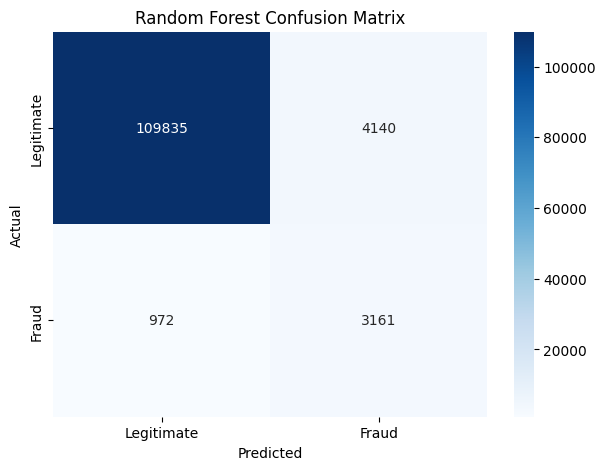

In [40]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

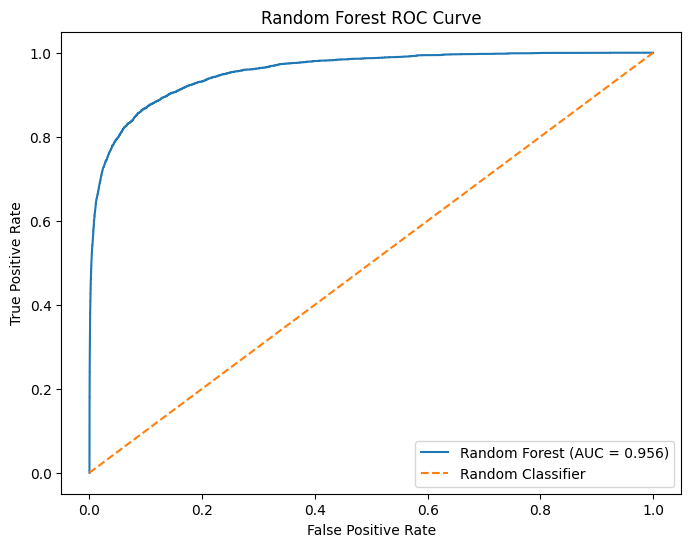

In [41]:
from sklearn.metrics import roc_curve

rf_fpr, rf_tpr, _ = roc_curve(
    y_test,
    rf_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curve")
plt.legend()

plt.show()

In [42]:
rf_train_pred = rf_model.predict(X_train)

rf_train_accuracy = accuracy_score(
    y_train,
    rf_train_pred
)

rf_test_accuracy = accuracy_score(
    y_test,
    rf_pred
)

print(f"Training Accuracy: {rf_train_accuracy * 100:.2f}%")
print(f"Testing Accuracy : {rf_test_accuracy * 100:.2f}%")
print(f"Difference       : {(rf_train_accuracy - rf_test_accuracy) * 100:.2f}%")

Training Accuracy: 96.53%
Testing Accuracy : 95.67%
Difference       : 0.85%


In [43]:
from xgboost import XGBClassifier

In [44]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("Scale Pos Weight:", scale_pos_weight)

Negative samples: 455902
Positive samples: 16530
Scale Pos Weight: 27.580278281911674


In [45]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created.")

XGBoost model created.


In [46]:
print("Training XGBoost...")

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost training completed.")

Training XGBoost...
XGBoost training completed.


In [47]:
xgb_pred = xgb_model.predict(X_test)

xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost predictions completed.")

XGBoost predictions completed.


In [48]:
xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

xgb_precision = precision_score(
    y_test,
    xgb_pred
)

xgb_recall = recall_score(
    y_test,
    xgb_pred
)

xgb_f1 = f1_score(
    y_test,
    xgb_pred
)

xgb_auc = roc_auc_score(
    y_test,
    xgb_prob
)

print("========== XGBOOST RESULTS ==========")
print(f"Accuracy : {xgb_accuracy * 100:.2f}%")
print(f"Precision: {xgb_precision * 100:.2f}%")
print(f"Recall   : {xgb_recall * 100:.2f}%")
print(f"F1 Score : {xgb_f1 * 100:.2f}%")
print(f"ROC-AUC  : {xgb_auc * 100:.2f}%")

========== XGBOOST RESULTS ==========
Accuracy : 89.30%
Precision: 22.51%
Recall   : 84.25%
F1 Score : 35.53%
ROC-AUC  : 94.70%


In [49]:
from sklearn.metrics import classification_report

print("========== XGBOOST CLASSIFICATION REPORT ==========")

print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["Legitimate", "Fraud"]
    )
)

========== XGBOOST CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

  Legitimate       0.99      0.89      0.94    113975
       Fraud       0.23      0.84      0.36      4133

    accuracy                           0.89    118108
   macro avg       0.61      0.87      0.65    118108
weighted avg       0.97      0.89      0.92    118108



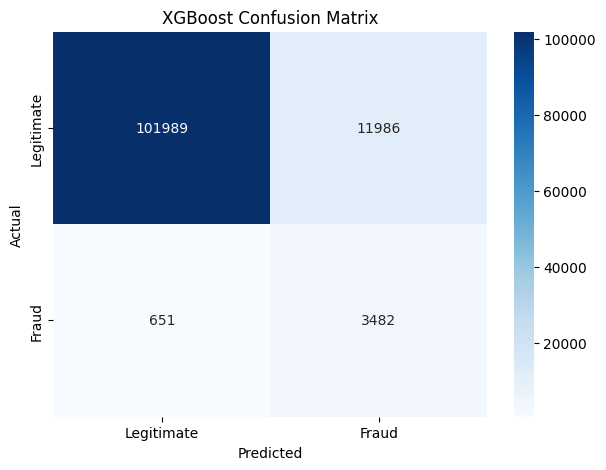

In [50]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

xgb_cm = confusion_matrix(y_test, xgb_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("XGBoost Confusion Matrix")

plt.show()

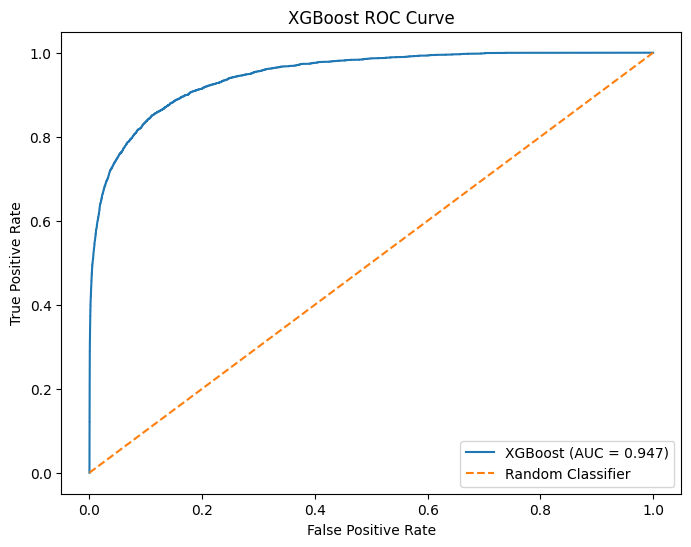

In [51]:
from sklearn.metrics import roc_curve

xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curve")
plt.legend()

plt.show()

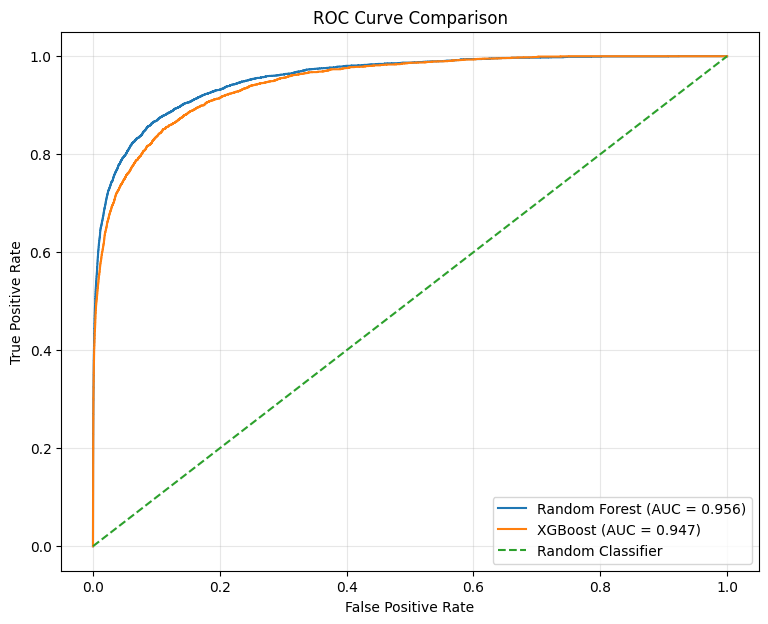

In [54]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
xgb_fpr, xgb_tpr, _ = roc_curve(y_test, xgb_prob)

plt.figure(figsize=(9, 7))

plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

plt.plot(
    xgb_fpr,
    xgb_tpr,
    label=f"XGBoost (AUC = {xgb_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 Random Forest Features:")
display(rf_importance.head(20))

Top 20 Random Forest Features:


,Feature,Importance
63,card1_historical_fraud_rate,0.217336
22,C5,0.044508
34,D3,0.038688
30,C13,0.037743
31,C14,0.036953
18,C1,0.032545
33,D2,0.030309
21,C4,0.027220
61,card1_txn_count,0.025902
17,recipient_email_domain,0.024827


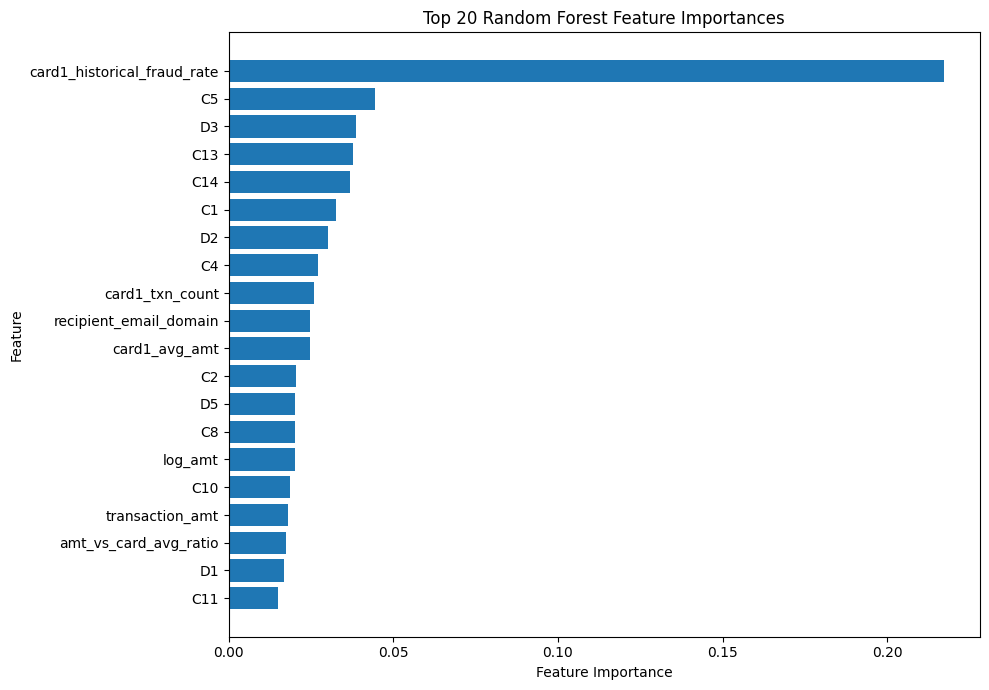

In [57]:
plt.figure(figsize=(10, 7))

top_rf = rf_importance.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_rf["Feature"],
    top_rf["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

In [58]:
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

xgb_importance = xgb_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 20 XGBoost Features:")
display(xgb_importance.head(20))

Top 20 XGBoost Features:


,Feature,Importance
63,card1_historical_fraud_rate,0.138008
25,C8,0.072693
22,C5,0.049051
31,C14,0.042871
34,D3,0.030204
21,C4,0.027081
5,has_identity,0.026373
33,D2,0.025895
18,C1,0.024091
44,M5_enc,0.021917


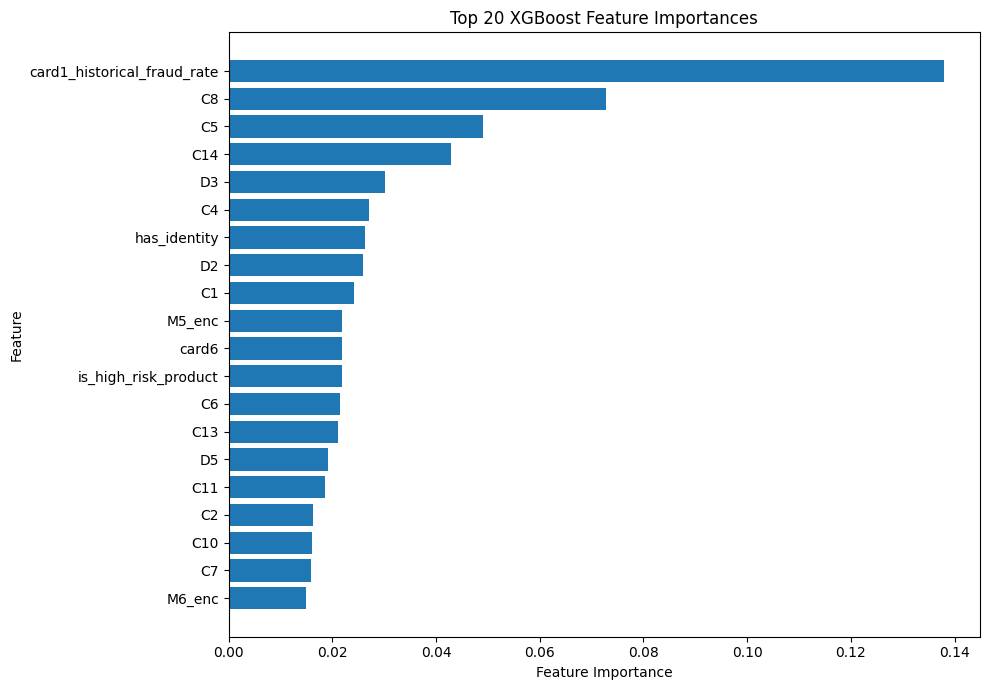

In [59]:
plt.figure(figsize=(10, 7))

top_xgb = xgb_importance.head(20).sort_values(
    by="Importance"
)

plt.barh(
    top_xgb["Feature"],
    top_xgb["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

In [60]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

# Random Forest - Training predictions
rf_train_pred = rf_model.predict(X_train)
rf_train_prob = rf_model.predict_proba(X_train)[:, 1]

# Training metrics
rf_train_accuracy = accuracy_score(y_train, rf_train_pred)
rf_train_f1 = f1_score(y_train, rf_train_pred)
rf_train_auc = roc_auc_score(y_train, rf_train_prob)

# Testing metrics
rf_test_accuracy = accuracy_score(y_test, rf_pred)
rf_test_f1 = f1_score(y_test, rf_pred)
rf_test_auc = roc_auc_score(y_test, rf_prob)

print("========== RANDOM FOREST OVERFITTING CHECK ==========")

print(f"Training Accuracy : {rf_train_accuracy * 100:.2f}%")
print(f"Testing Accuracy  : {rf_test_accuracy * 100:.2f}%")

print(f"\nTraining F1       : {rf_train_f1 * 100:.2f}%")
print(f"Testing F1        : {rf_test_f1 * 100:.2f}%")

print(f"\nTraining ROC-AUC   : {rf_train_auc * 100:.2f}%")
print(f"Testing ROC-AUC    : {rf_test_auc * 100:.2f}%")

print("\nDifferences:")

print(
    f"Accuracy Gap : "
    f"{(rf_train_accuracy - rf_test_accuracy) * 100:.2f}%"
)

print(
    f"F1 Gap       : "
    f"{(rf_train_f1 - rf_test_f1) * 100:.2f}%"
)

print(
    f"ROC-AUC Gap  : "
    f"{(rf_train_auc - rf_test_auc) * 100:.2f}%"
)

========== RANDOM FOREST OVERFITTING CHECK ==========
Training Accuracy : 96.53%
Testing Accuracy  : 95.67%

Training F1       : 64.45%
Testing F1        : 55.29%

Training ROC-AUC   : 98.82%
Testing ROC-AUC    : 95.60%

Differences:
Accuracy Gap : 0.85%
F1 Gap       : 9.16%
ROC-AUC Gap  : 3.22%


In [61]:
# XGBoost - Training predictions
xgb_train_pred = xgb_model.predict(X_train)
xgb_train_prob = xgb_model.predict_proba(X_train)[:, 1]

# Training metrics
xgb_train_accuracy = accuracy_score(y_train, xgb_train_pred)
xgb_train_f1 = f1_score(y_train, xgb_train_pred)
xgb_train_auc = roc_auc_score(y_train, xgb_train_prob)

# Testing metrics
xgb_test_accuracy = accuracy_score(y_test, xgb_pred)
xgb_test_f1 = f1_score(y_test, xgb_pred)
xgb_test_auc = roc_auc_score(y_test, xgb_prob)

print("========== XGBOOST OVERFITTING CHECK ==========")

print(f"Training Accuracy : {xgb_train_accuracy * 100:.2f}%")
print(f"Testing Accuracy  : {xgb_test_accuracy * 100:.2f}%")

print(f"\nTraining F1       : {xgb_train_f1 * 100:.2f}%")
print(f"Testing F1        : {xgb_test_f1 * 100:.2f}%")

print(f"\nTraining ROC-AUC   : {xgb_train_auc * 100:.2f}%")
print(f"Testing ROC-AUC    : {xgb_test_auc * 100:.2f}%")

print("\nDifferences:")

print(
    f"Accuracy Gap : "
    f"{(xgb_train_accuracy - xgb_test_accuracy) * 100:.2f}%"
)

print(
    f"F1 Gap       : "
    f"{(xgb_train_f1 - xgb_test_f1) * 100:.2f}%"
)

print(
    f"ROC-AUC Gap  : "
    f"{(xgb_train_auc - xgb_test_auc) * 100:.2f}%"
)

========== XGBOOST OVERFITTING CHECK ==========
Training Accuracy : 89.66%
Testing Accuracy  : 89.30%

Training F1       : 37.13%
Testing F1        : 35.53%

Training ROC-AUC   : 95.97%
Testing ROC-AUC    : 94.70%

Differences:
Accuracy Gap : 0.36%
F1 Gap       : 1.60%
ROC-AUC Gap  : 1.27%


-------------------------------
# **Comparision Table**
---------------------------

In [62]:
comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Random Forest": [
        rf_accuracy * 100,
        rf_precision * 100,
        rf_recall * 100,
        rf_f1 * 100,
        rf_auc * 100
    ],
    "XGBoost": [
        xgb_accuracy * 100,
        xgb_precision * 100,
        xgb_recall * 100,
        xgb_f1 * 100,
        xgb_auc * 100
    ]
})

comparison["Random Forest"] = comparison["Random Forest"].round(2)
comparison["XGBoost"] = comparison["XGBoost"].round(2)

display(comparison)

,Metric,Random Forest,XGBoost
0,Accuracy,95.67,89.30
1,Precision,43.30,22.51
2,Recall,76.48,84.25
3,F1 Score,55.29,35.53
4,ROC-AUC,95.60,94.70


In [63]:
import pickle

# Save Random Forest
with open("random_forest_fraud_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

# Save XGBoost
with open("xgboost_fraud_model.pkl", "wb") as file:
    pickle.dump(xgb_model, file)

print("Models saved successfully!")
print("random_forest_fraud_model.pkl")
print("xgboost_fraud_model.pkl")

Models saved successfully!
random_forest_fraud_model.pkl
xgboost_fraud_model.pkl


In [64]:
import os

print("Random Forest file size:",
      round(os.path.getsize("random_forest_fraud_model.pkl") / (1024 * 1024), 2),
      "MB")

print("XGBoost file size:",
      round(os.path.getsize("xgboost_fraud_model.pkl") / (1024 * 1024), 2),
      "MB")

Random Forest file size: 39.47 MB
XGBoost file size: 0.76 MB


In [65]:
with open("feature_columns.pkl", "wb") as file:
    pickle.dump(list(X_train.columns), file)

print("Feature columns saved successfully!")
print("Number of features:", len(X_train.columns))

Feature columns saved successfully!
Number of features: 68


In [66]:
from google.colab import files

files.download("random_forest_fraud_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
files.download("xgboost_fraud_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [68]:
files.download("feature_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
print("Dataset shape:", df.shape)

Dataset shape: (590540, 72)


In [70]:
df.to_csv("IEEE_CIS_Fraud_Detection_Complete.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [72]:
import os

file_size = os.path.getsize("IEEE_CIS_Fraud_Detection_Complete.csv")

print("File size:",
      round(file_size / (1024 * 1024), 2),
      "MB")

File size: 197.94 MB


In [73]:
from google.colab import files

files.download("IEEE_CIS_Fraud_Detection_Complete.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [74]:
# Combine preprocessed features with target variable
cleaned_df = X.copy()
cleaned_df["is_fraud"] = y.values

print("Cleaned dataset shape:", cleaned_df.shape)
print("Missing values:", cleaned_df.isnull().sum().sum())
print("Non-numeric columns:", cleaned_df.select_dtypes(include=["object"]).shape[1])

Cleaned dataset shape: (590540, 69)
Missing values: 0
Non-numeric columns: 0


In [75]:
cleaned_df.to_csv(
    "IEEE_CIS_Fraud_Detection_Cleaned_Preprocessed.csv",
    index=False
)

print("Cleaned preprocessed dataset saved successfully!")

Cleaned preprocessed dataset saved successfully!


In [76]:
import os

file_size = os.path.getsize(
    "IEEE_CIS_Fraud_Detection_Cleaned_Preprocessed.csv"
)

print(
    "File size:",
    round(file_size / (1024 * 1024), 2),
    "MB"
)

File size: 223.64 MB


In [77]:
from google.colab import files

files.download(
    "IEEE_CIS_Fraud_Detection_Cleaned_Preprocessed.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [85]:
import pickle

with open("fraud_model.pkl", "wb") as file:
    pickle.dump(rf_model, file)

print("fraud_model.pkl created successfully!")

fraud_model.pkl created successfully!


In [86]:
with open("feature_columns.pkl", "wb") as file:
    pickle.dump(list(X_train.columns), file)

print("feature_columns.pkl created successfully!")

feature_columns.pkl created successfully!


In [87]:
from google.colab import files

files.download("fraud_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:
files.download("feature_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [89]:
import sklearn
import numpy

print("scikit-learn:", sklearn.__version__)
print("numpy:", numpy.__version__)

scikit-learn: 1.6.1
numpy: 2.1.3


In [90]:
sample = X_test.iloc[[0]]

sample.to_csv("test_transaction.csv", index=False)

from google.colab import files
files.download("test_transaction.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [91]:
import pickle

# Save the median values used for the numerical features
feature_medians = X.median().to_dict()

# Save frequency mappings for categorical columns
categorical_columns = [
    "product_cd",
    "card4",
    "card6",
    "purchaser_email_domain",
    "recipient_email_domain",
    "device_type"
]

frequency_mappings = {}

for col in categorical_columns:
    if col in df.columns:
        frequency_mappings[col] = (
            df[col].value_counts(normalize=True).to_dict()
        )

# Save preprocessing information
preprocessing_artifacts = {
    "feature_medians": feature_medians,
    "frequency_mappings": frequency_mappings,
    "categorical_columns": categorical_columns,
    "feature_columns": list(X.columns)
}

with open("preprocessing_artifacts.pkl", "wb") as file:
    pickle.dump(preprocessing_artifacts, file)

print("preprocessing_artifacts.pkl created successfully!")

preprocessing_artifacts.pkl created successfully!


In [92]:
from google.colab import files

files.download("preprocessing_artifacts.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [93]:
# Find one real fraud transaction
fraud_index = y_test[y_test == 1].index[0]

fraud_transaction = X_test.loc[[fraud_index]]

fraud_transaction.to_csv(
    "test_fraud_transaction.csv",
    index=False
)


# Find one real legitimate transaction
legitimate_index = y_test[y_test == 0].index[0]

legitimate_transaction = X_test.loc[[legitimate_index]]

legitimate_transaction.to_csv(
    "test_legitimate_transaction.csv",
    index=False
)

print("Fraud transaction:", fraud_transaction.shape)
print("Legitimate transaction:", legitimate_transaction.shape)

Fraud transaction: (1, 68)
Legitimate transaction: (1, 68)


In [94]:
from google.colab import files

files.download("test_fraud_transaction.csv")
files.download("test_legitimate_transaction.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>